# UTS GRAF SAINS DATA

- NAMA: ALIFIYANTI PUTRI NUR AZIZAH
- NIM: 24031554032
- KELAS: 2024B

SPLIT PERIODE: P1 (01–15 Agt 2015) | P2 (01–18 Sept 2015)

## Download Data

In [16]:
# Mengunduh dataset dari Kaggle dan menyimpannya sebagai ecommerce-dataset.zip
# !curl -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

## 0. Library dan Konfigurasi

In [17]:
# Jika diperlukan, jalankan sekali di environment notebook:
# %pip install pandas numpy scipy scikit-learn networkx matplotlib neo4j tqdm

from pathlib import Path
import os
import getpass
import math
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase
from tqdm.auto import tqdm

DATA_PATH = Path("events.csv")
NEO4J_URI = os.getenv("NEO4J_URI", "bolt://localhost:7687")
NEO4J_USER = os.getenv("NEO4J_USER", "neo4j")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD") or getpass.getpass("Password Neo4j: ")
NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", "neo4j")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File {DATA_PATH.resolve()} tidak ditemukan. Letakkan events.csv di folder notebook."
    )

print("File data ditemukan:", DATA_PATH.resolve())
print("URI Neo4j:", NEO4J_URI)
print("Database:", NEO4J_DATABASE)

File data ditemukan: D:\KULYEAH\SEM 5\GRAF SAINS DATA\UTS GRAF SAINS DATA\events.csv
URI Neo4j: bolt://localhost:7687
Database: neo4j


## 2.1  Wrangling dan EDA

### Soal 1 - 2

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama!

    P1 (01–15 Agt 2015) | P2 (01–18 Sept 2015)

2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [18]:
print("Membaca data RetailRocket...")
df = pd.read_csv(DATA_PATH)
required_cols = {"timestamp", "visitorid", "event", "itemid", "transactionid"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing_cols)}")

# Timestamp sumber adalah Unix epoch dalam milidetik (UTC).
df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
df = df.dropna(subset=["timestamp", "visitorid", "itemid", "event"]).copy()
df["timestamp"] = df["timestamp"].astype("int64")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True).dt.tz_localize(None)

# Pilihan nomor 35:
# P1 = 1–15 Agustus 2015 (tanggal akhir eksklusif: 16 Agustus)
# P2 = 1–18 September 2015 (tanggal akhir eksklusif: 19 September)
P1_START = pd.Timestamp("2015-08-01")
P1_END_EXCLUSIVE = pd.Timestamp("2015-08-16")
P2_START = pd.Timestamp("2015-09-01")
P2_END_EXCLUSIVE = pd.Timestamp("2015-09-19")

p1_train = df.loc[
    (df["datetime"] >= P1_START) & (df["datetime"] < P1_END_EXCLUSIVE)
].copy()
p2_test = df.loc[
    (df["datetime"] >= P2_START) & (df["datetime"] < P2_END_EXCLUSIVE)
].copy()

# Simpan hanya data pada rentang yang ditetapkan.
p1_train.to_csv("events_train_P1.csv", index=False)
p2_test.to_csv("events_test_P2.csv", index=False)

print(f"Rentang data sumber : {df['datetime'].min()} s.d. {df['datetime'].max()}")
print(f"P1 yang dipilih     : {P1_START.date()} s.d. {(P1_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}")
print(f"P2 yang dipilih     : {P2_START.date()} s.d. {(P2_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}")
print(f"Training P1         : {len(p1_train):,} baris")
print(f"Testing P2          : {len(p2_test):,} baris")
print("CSV tersimpan: events_train_P1.csv dan events_test_P2.csv")
print("\nKomposisi event P1:")
display(p1_train["event"].value_counts().rename_axis("event").to_frame("jumlah"))
print("\nKomposisi event P2:")
display(p2_test["event"].value_counts().rename_axis("event").to_frame("jumlah"))

Membaca data RetailRocket...
Rentang data sumber : 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000
P1 yang dipilih     : 2015-08-01 s.d. 2015-08-15
P2 yang dipilih     : 2015-09-01 s.d. 2015-09-18
Training P1         : 265,509 baris
Testing P2          : 303,710 baris
CSV tersimpan: events_train_P1.csv dan events_test_P2.csv

Komposisi event P1:


,jumlah
event,
view,256371
addtocart,7047
transaction,2091



Komposisi event P2:


,jumlah
event,
view,293660
addtocart,7681
transaction,2369


Pada bagian ini, data interaksi dibagi menjadi dua periode yang berbeda. Periode P1 (1–15 Agustus 2015) digunakan sebagai data training, sedangkan periode P2 (1–18 September 2015) digunakan sebagai data testing. Pemfilteran dilakukan pada kolom timestamp yang terlebih dahulu dikonversi dari Unix epoch dalam milidetik menjadi format tanggal dan waktu.

Batas akhir pada kode dibuat eksklusif, yaitu 16 Agustus untuk P1 dan 19 September untuk P2. Dengan demikian, tanggal 15 Agustus dan 18 September tetap masuk ke periode masing-masing. Data yang berada di luar kedua rentang tersebut tidak dimasukkan ke file hasil split. Kedua hasil disimpan sebagai `events_train_P1.csv` dan `events_test_P2.csv`.

Hasil pemfilteran menghasilkan 265.509 baris pada P1 (256.371 view, 7.047 addtocart, 2.091 transaction) dan 303.710 baris pada P2 (293.660 view, 7.681 addtocart, 2.369 transaction). Pada kedua periode, view mendominasi (lebih dari 96% baris), sedangkan transaction hanya sekitar 0,8%.

### Soal 3

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [19]:
# Verifikasi koneksi Neo4j
with GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
) as driver:

    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil.")

    with driver.session(database=NEO4J_DATABASE) as session:

        # Hapus node secara bertahap agar penggunaan memori lebih kecil
        total_deleted = 0

        while True:
            result = session.run("""
                MATCH (n:RR_RetailRocket)
                WITH n
                LIMIT 200
                DETACH DELETE n
                RETURN count(n) AS deleted
            """)

            deleted = result.single()["deleted"]
            total_deleted += deleted

            if deleted == 0:
                break

            print(f"Node terhapus: {total_deleted}")

        # Pastikan constraint tersedia
        session.run("""
            CREATE CONSTRAINT rr_visitor_id_unique IF NOT EXISTS
            FOR (v:RRVisitor)
            REQUIRE v.visitorid IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT rr_item_id_unique IF NOT EXISTS
            FOR (i:RRItem)
            REQUIRE i.itemid IS UNIQUE
        """).consume()

        print(f"Total node terhapus: {total_deleted}")
        print("Constraint berhasil diperiksa/dibuat.")


Koneksi Neo4j berhasil.
Node terhapus: 200
Node terhapus: 400
Node terhapus: 600
Node terhapus: 800
Node terhapus: 1000
Node terhapus: 1200
Node terhapus: 1400
Node terhapus: 1600
Node terhapus: 1800
Node terhapus: 2000
Node terhapus: 2200
Node terhapus: 2400
Node terhapus: 2600
Node terhapus: 2800
Node terhapus: 3000
Node terhapus: 3200
Node terhapus: 3400
Node terhapus: 3600
Node terhapus: 3800
Node terhapus: 4000
Node terhapus: 4200
Node terhapus: 4400
Node terhapus: 4600
Node terhapus: 4800
Node terhapus: 5000
Node terhapus: 5200
Node terhapus: 5400
Node terhapus: 5600
Node terhapus: 5800
Node terhapus: 6000
Node terhapus: 6200
Node terhapus: 6400
Node terhapus: 6600
Node terhapus: 6800
Node terhapus: 7000
Node terhapus: 7200
Node terhapus: 7400
Node terhapus: 7600
Node terhapus: 7800
Node terhapus: 8000
Node terhapus: 8200
Node terhapus: 8400
Node terhapus: 8600
Node terhapus: 8800
Node terhapus: 9000
Node terhapus: 9200
Node terhapus: 9400
Node terhapus: 9600
Node terhapus: 9800


In [20]:
def import_batch(tx, rows):
    query = """
    UNWIND $rows AS row
    MERGE (v:RR_RetailRocket:Visitor:RRVisitor {visitorid: row.visitorid})
    MERGE (i:RR_RetailRocket:Item:RRItem {itemid: row.itemid})
    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    )
    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    )
    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    )
    """
    tx.run(query, rows=rows)

# Impor P1 saja agar data testing tidak bocor ke proses pembentukan rekomendasi.
cols_to_import = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
train_import = p1_train[cols_to_import].copy()
train_import["visitorid"] = train_import["visitorid"].astype("int64")
train_import["itemid"] = train_import["itemid"].astype("int64")
train_import["timestamp"] = train_import["timestamp"].astype("int64")
train_import["transactionid"] = train_import["transactionid"].where(train_import["transactionid"].notna(), "").astype(str)

BATCH_SIZE = 5000
with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    driver.verify_connectivity()
    with driver.session(database=NEO4J_DATABASE) as session:
        for start in tqdm(range(0, len(train_import), BATCH_SIZE), desc="Impor P1 ke Neo4j"):
            batch_df = train_import.iloc[start:start + BATCH_SIZE]
            rows = batch_df.to_dict(orient="records")
            session.execute_write(import_batch, rows)

print(f"Impor selesai: {len(train_import):,} baris P1 diproses.")

Impor P1 ke Neo4j: 100%|██████████| 54/54 [00:35<00:00,  1.54it/s]

Impor selesai: 265,509 baris P1 diproses.


In [21]:
composition_query = """
MATCH (n)
WHERE n:RR_RetailRocket AND (n:Visitor OR n:Item)
UNWIND labels(n) AS label
WITH label, count(DISTINCT n) AS jumlah
WHERE label IN ['Visitor', 'Item']
RETURN label, jumlah
ORDER BY label
"""
relationship_query = """
MATCH (v:RR_RetailRocket:Visitor)-[r]->(i:RR_RetailRocket:Item)
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jenis_relasi
"""

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        node_rows = [record.data() for record in session.run(composition_query)]
        rel_rows = [record.data() for record in session.run(relationship_query)]

print("Komposisi node:")
display(pd.DataFrame(node_rows))
print("Komposisi relasi:")
display(pd.DataFrame(rel_rows))

print("\nPenjelasan query: MATCH (n) mencari node, WHERE membatasi pada label Visitor/Item,")
print("UNWIND labels(n) memecah label, dan count(DISTINCT n) menghitung node unik per label.")
print("Query kedua menghitung jumlah relasi interaksi berdasarkan tipe relasi.")

Komposisi node:


,label,jumlah
0,Item,76078
1,Visitor,153836


Komposisi relasi:


,jenis_relasi,jumlah
0,ADDED_TO_CART,6991
1,BOUGHT,2091
2,VIEWED,256361



Penjelasan query: MATCH (n) mencari node, WHERE membatasi pada label Visitor/Item,
UNWIND labels(n) memecah label, dan count(DISTINCT n) menghitung node unik per label.
Query kedua menghitung jumlah relasi interaksi berdasarkan tipe relasi.


Subgraph yang dibangun terdiri dari dua jenis simpul utama, yaitu Visitor dan Item. Simpul Visitor mewakili pengguna yang melakukan interaksi, sedangkan simpul Item mewakili produk yang diakses pengguna. Hubungan di antara keduanya menunjukkan aktivitas pengguna terhadap item.

Query `composition_query` menggunakan `MATCH (n)` untuk mencari node, kemudian `WHERE` membatasi pencarian pada node yang memiliki label `RR_RetailRocket` dan label `Visitor` atau `Item`. Bagian `UNWIND labels(n)` memisahkan label node, sedangkan `count(DISTINCT n)` menghitung node unik untuk setiap jenis. Hasilnya diurutkan berdasarkan nama label.

Query `relationship_query` mencari relasi dari Visitor menuju Item. Fungsi `type(r)` mengambil jenis relasi, seperti `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`, dan `count(r)` menghitung jumlah relasi untuk masing-masing jenis. Kedua query dijalankan melalui Python API Neo4j menggunakan `driver.session()` dan hasilnya dikonversi menjadi DataFrame Pandas agar mudah dibaca.

Subgraf P1 terdiri dari 153.836 simpul Visitor dan 76.078 simpul Item, dengan relasi VIEWED (256.361), ADDED_TO_CART (6.991), dan BOUGHT (2.091). Jumlah relasi VIEWED dan ADDED_TO_CART sedikit lebih kecil daripada jumlah baris di CSV (256.371 dan 7.047) karena impor memakai MERGE, sehingga event identik dengan timestamp yang sama pada Visitor dan Item yang sama tersimpan sebagai satu relasi. Data yang diimpor hanya berasal dari P1 agar P2 tetap menjadi data pengujian.

### Soal 4 - 6

4.  Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Bipartite graph:
- Node User: 1,918; Node Item: 1,869
- Interaksi unik dalam sampel: 1,994

Matriks VSM user-item shape: (1918, 1869); jumlah nilai nonzero: 1,994

Proyeksi User: 1,918 node, 179 edge
Proyeksi Item: 1,869 node, 209 edge
Matriks adjacency User-User shape: (1918, 1918)
Matriks adjacency Item-Item shape: (1869, 1869)


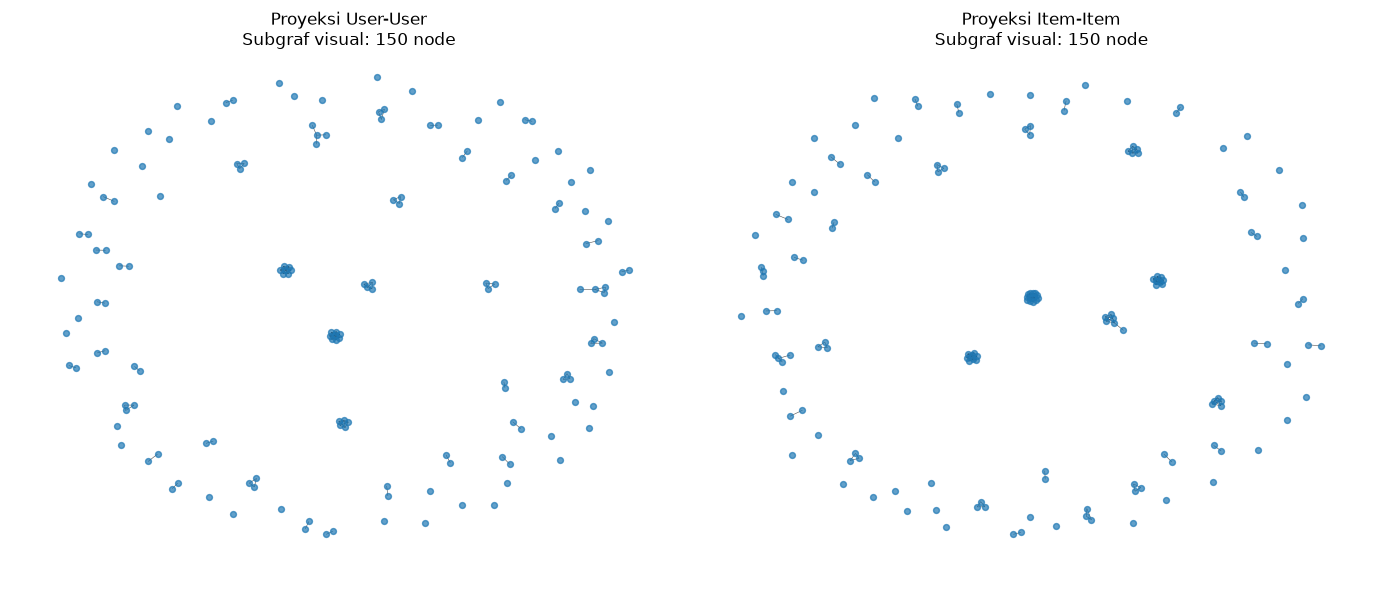

In [22]:
SEED = 42
SAMPLE_N = min(2000, len(p1_train))
sample_df = p1_train.sample(n=SAMPLE_N, random_state=SEED).copy()
sample_pairs = sample_df[["visitorid", "itemid"]].drop_duplicates()

B = nx.Graph()
user_nodes = [f"V_{int(x)}" for x in sample_pairs["visitorid"].unique()]
item_nodes = [f"I_{int(x)}" for x in sample_pairs["itemid"].unique()]
B.add_nodes_from(user_nodes, bipartite=0, node_type="User")
B.add_nodes_from(item_nodes, bipartite=1, node_type="Item")
B.add_edges_from(
    (f"V_{int(v)}", f"I_{int(i)}")
    for v, i in sample_pairs.itertuples(index=False, name=None)
)

users = {n for n, d in B.nodes(data=True) if d["bipartite"] == 0}
items = set(B) - users
user_projection = nx.bipartite.weighted_projected_graph(B, users)
item_projection = nx.bipartite.weighted_projected_graph(B, items)

# Matriks VSM: baris = user, kolom = item; nilai 1 menandakan ada interaksi pada sampel.
user_order = sorted(users)
item_order = sorted(items)
A = nx.bipartite.biadjacency_matrix(B, row_order=user_order, column_order=item_order, dtype=np.uint8, weight=None)

print("Bipartite graph:")
print(f"- Node User: {len(users):,}; Node Item: {len(items):,}")
print(f"- Interaksi unik dalam sampel: {B.number_of_edges():,}")
print(f"\nMatriks VSM user-item shape: {A.shape}; jumlah nilai nonzero: {A.nnz:,}")
print(f"\nProyeksi User: {user_projection.number_of_nodes():,} node, {user_projection.number_of_edges():,} edge")
print(f"Proyeksi Item: {item_projection.number_of_nodes():,} node, {item_projection.number_of_edges():,} edge")
print(f"Matriks adjacency User-User shape: {(len(users), len(users))}")
print(f"Matriks adjacency Item-Item shape: {(len(items), len(items))}")

# Visualisasi ringkas: tampilkan hingga 150 node berderajat tertinggi pada masing-masing proyeksi.
def plot_projection(G, title, ax, max_nodes=150):
    if G.number_of_nodes() == 0:
        ax.set_title(title + " (kosong)")
        ax.axis("off")
        return
    chosen = sorted(G.degree, key=lambda x: x[1], reverse=True)[:max_nodes]
    H = G.subgraph([n for n, _ in chosen]).copy()
    pos = nx.spring_layout(H, seed=SEED, k=None)
    nx.draw_networkx(H, pos=pos, ax=ax, with_labels=False, node_size=18, width=0.4, alpha=0.7)
    ax.set_title(f"{title}\nSubgraf visual: {H.number_of_nodes()} node")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_projection(user_projection, "Proyeksi User-User", axes[0])
plot_projection(item_projection, "Proyeksi Item-Item", axes[1])
plt.tight_layout()
plt.show()

Untuk membentuk VSM, data P1 diambil menggunakan sampel acak maksimal 2.000 baris dengan `random_state=42`, sehingga proses sampling dapat direproduksi. Pasangan `visitorid` dan `itemid` yang duplikat dihilangkan, lalu dibuat graf bipartit: simpul User dan Item berada pada dua kelompok berbeda, dan edge menunjukkan adanya interaksi di antara keduanya.

VSM User direpresentasikan oleh matriks biadjacency `A`, dengan baris sebagai User dan kolom sebagai Item. Nilai 1 menunjukkan bahwa pasangan User–Item tersebut memiliki interaksi pada sampel. Karena itu, bentuk matriksnya adalah `(jumlah User, jumlah Item)`. Banyaknya nilai nonzero `(A.nnz)` menunjukkan jumlah pasangan interaksi unik yang tersimpan.

VSM Item dapat dipahami melalui proyeksi Item–Item. Dua simpul Item dihubungkan jika keduanya memiliki keterkaitan melalui User yang sama. Bobot edge pada proyeksi ini menunjukkan banyaknya tetangga bersama pada graf bipartit. Matriks adjacency proyeksi User–User berbentuk `(jumlah User, jumlah User)`, sedangkan proyeksi Item–Item berbentuk `(jumlah Item, jumlah Item)`.

Plot NetworkX memperlihatkan subgraf ringkas dari masing-masing proyeksi. Untuk menjaga visualisasi tetap terbaca, kode hanya menggambar hingga 150 node dengan derajat tertinggi pada setiap proyeksi dan tidak menampilkan label node. Oleh karena itu, plot merupakan gambaran bagian graf, bukan seluruh simpul pada proyeksi. Sampel menghasilkan 1.918 simpul User dan 1.869 simpul Item dengan 1.994 interaksi unik. Matriks VSM user-item berukuran (1918 × 1869), dengan proyeksi User-User sebesar 179 edge dan proyeksi Item-Item sebesar 209 edge.

In [23]:
# VSM User: tiap baris = vektor satu User di ruang Item
A_user = A.tocsr()
# VSM Item: tiap baris = vektor satu Item di ruang User (transpose)
A_item = A.T.tocsr()

n_user, n_item = A_user.shape
total_sel = n_user * n_item
density = A_user.nnz / total_sel

print("VSM User")
print(f"- Shape        : {A_user.shape} (baris = User, kolom = Item)")
print(f"- Dimensi vektor tiap User : {A_user.shape[1]:,} (jumlah Item)")
print("\nVSM Item")
print(f"- Shape        : {A_item.shape} (baris = Item, kolom = User)")
print(f"- Dimensi vektor tiap Item : {A_item.shape[1]:,} (jumlah User)")

print(f"\nNilai nonzero  : {A_user.nnz:,}")
print(f"Total sel      : {total_sel:,}")
print(f"Kepadatan      : {density:.6f} ({density*100:.4f}%)")
print(f"Sparsity       : {(1-density)*100:.4f}%")

item_per_user = np.asarray(A_user.sum(axis=1)).ravel()
user_per_item = np.asarray(A_item.sum(axis=1)).ravel()
print(f"\nItem per User  : rata-rata {item_per_user.mean():.2f}, maks {int(item_per_user.max())}")
print(f"User per Item  : rata-rata {user_per_item.mean():.2f}, maks {int(user_per_item.max())}")

VSM User
- Shape        : (1918, 1869) (baris = User, kolom = Item)
- Dimensi vektor tiap User : 1,869 (jumlah Item)

VSM Item
- Shape        : (1869, 1918) (baris = Item, kolom = User)
- Dimensi vektor tiap Item : 1,918 (jumlah User)

Nilai nonzero  : 1,994
Total sel      : 3,584,742
Kepadatan      : 0.000556 (0.0556%)
Sparsity       : 99.9444%

Item per User  : rata-rata 1.04, maks 13
User per Item  : rata-rata 1.07, maks 8


VSM Item. Pada VSM Item, setiap Item direpresentasikan sebagai vektor di ruang User. Matriks item-user diperoleh dari transpose matriks user-item, sehingga berukuran (1869 × 1918): 1.869 baris untuk Item dan 1.918 kolom (dimensi) untuk User. Dengan demikian, dimensi vektor Item adalah 1.918, sedangkan dimensi vektor User pada Soal 4 adalah 1.869.

Kedua matriks memuat 1.994 nilai nonzero dari 3.584.742 sel, atau kepadatan sekitar 0,056% (sparsity sekitar 99,94%). Rata-rata satu User hanya berinteraksi dengan sekitar 1,04 Item (maksimum 13 Item), dan rata-rata satu Item diakses oleh sekitar 1,07 User (maksimum 8 User). Sebagian besar vektor hanya memiliki satu nilai 1 di antara ribuan dimensi, sehingga ruang vektornya sangat jarang dan sebagian besar pasangan vektor tidak beririsan. Karena itu, representasi sparse (CSR) dipakai untuk menghemat memori.

Plot NetworkX pada proyeksi Item-Item menunjukkan hubungan antar-Item yang terbentuk karena diakses oleh User yang sama. Hanya 150 node berderajat tertinggi yang ditampilkan agar plot terbaca.

### Soal 6

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Jawab:

Berdasarkan eksplorasi VSM pada Soal 4 dan 5, proyeksi Item-Item lebih baik dibanding proyeksi User-User, meskipun selisihnya tipis.

Efisiensi (ukuran). Matriks user-item berukuran (1918 × 1869). Proyeksi User-User menghasilkan matriks adjacency (1918 × 1918) atau sekitar 3,68 juta sel, sedangkan proyeksi Item-Item menghasilkan (1869 × 1869) atau sekitar 3,49 juta sel. Proyeksi Item-Item lebih kecil sekitar 5%, karena jumlah Item (1.869) lebih sedikit daripada jumlah User (1.918).

Efektivitas (keterhubungan). Proyeksi User-User hanya memiliki 179 edge, sedangkan proyeksi Item-Item memiliki 209 edge, padahal node-nya lebih sedikit. Kepadatannya karena itu lebih tinggi pada proyeksi Item (sekitar 1,2 × 10⁻⁴ dibanding 9,7 × 10⁻⁵ pada proyeksi User), dan rata-rata derajat node juga lebih besar (sekitar 0,22 dibanding 0,19). Artinya, hubungan antar-item lebih banyak terbentuk daripada hubungan antar-user. Untuk tujuan rekomendasi, proyeksi ini juga lebih langsung, karena yang dicari adalah item yang mirip, dan hubungannya sudah tersedia dalam bentuk edge Item-Item.

Catatan. Kedua proyeksi sangat jarang (sparse): dari 1.994 interaksi unik, hanya sedikit simpul yang terhubung, sehingga sebagian besar node berdiri sendiri. Plot NetworkX hanya menampilkan 150 node berderajat tertinggi agar terbaca. Karena selisih ukuran dan jumlah edge kedua proyeksi kecil, kesimpulan ini bersifat indikatif dan bergantung pada sampel 2.000 baris yang digunakan.

### Soal 7

7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

    a.  Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

    b. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [24]:
N_CATALOG = min(500, p1_train["itemid"].nunique())
TOP_NEIGHBORS = 5

popular_item_ids = (
    p1_train.groupby("itemid").size().sort_values(ascending=False).head(N_CATALOG).index.astype("int64").tolist()
)
item_to_row = {int(item_id): idx for idx, item_id in enumerate(popular_item_ids)}
filtered = p1_train.loc[p1_train["itemid"].isin(popular_item_ids), ["visitorid", "itemid"]].drop_duplicates()
visitor_ids = filtered["visitorid"].drop_duplicates().astype("int64").tolist()
visitor_to_col = {int(visitor_id): idx for idx, visitor_id in enumerate(visitor_ids)}

row_idx = filtered["itemid"].astype("int64").map(item_to_row).to_numpy()
col_idx = filtered["visitorid"].astype("int64").map(visitor_to_col).to_numpy()
item_user_matrix = sp.csr_matrix(
    (np.ones(len(filtered), dtype=np.float32), (row_idx, col_idx)),
    shape=(len(popular_item_ids), len(visitor_ids)),
    dtype=np.float32,
)
item_user_matrix.data[:] = 1.0

# Hasil similarity hanya 500 x 500, bukan matriks dense 76.078 x 76.078 (seluruh item P1).
item_sim = cosine_similarity(item_user_matrix, dense_output=True)
item_ids = [int(x) for x in popular_item_ids]
print(f"Katalog item: {len(item_ids):,}")
print(f"Matriks item-user shape: {item_user_matrix.shape}; nonzero: {item_user_matrix.nnz:,}")
print(f"Matriks cosine similarity shape: {item_sim.shape}")

# Ambil item acuan yang memiliki tetangga positif terbanyak; deterministic dari katalog terurut.
positive_neighbor_counts = ((item_sim > 0).sum(axis=1) - 1)
anchor_idx = int(np.argmax(positive_neighbor_counts))
anchor_item = item_ids[anchor_idx]
sim_scores = item_sim[anchor_idx].copy()
sim_scores[anchor_idx] = -1.0
similar_indices = [int(i) for i in np.argsort(sim_scores)[::-1] if sim_scores[i] > 0][:5]

print(f"\nItem acuan: {anchor_item}")
if similar_indices:
    top_similar = pd.DataFrame({
        "item_acuan": anchor_item,
        "item_mirip": [item_ids[i] for i in similar_indices],
        "cosine_similarity": [float(sim_scores[i]) for i in similar_indices],
    })
    display(top_similar)
else:
    top_similar = pd.DataFrame(columns=["item_acuan", "item_mirip", "cosine_similarity"])
    print("Tidak ditemukan item lain dengan similarity positif pada katalog ini.")

Katalog item: 500
Matriks item-user shape: (500, 20184); nonzero: 23,903
Matriks cosine similarity shape: (500, 500)

Item acuan: 461686


,item_acuan,item_mirip,cosine_similarity
0,461686,218794,0.369587
1,461686,171878,0.364938
2,461686,10572,0.212709
3,461686,119736,0.103271
4,461686,183758,0.085868


In [25]:
similarity_rows = []
for i, item_id in enumerate(item_ids):
    scores = item_sim[i].copy()
    scores[i] = -1.0  # item tidak boleh menjadi tetangga dirinya sendiri
    neighbor_idx = [int(j) for j in np.argsort(scores)[::-1] if scores[j] > 0][:TOP_NEIGHBORS]
    for j in neighbor_idx:
        similarity_rows.append({
            "item1": int(item_id),
            "item2": int(item_ids[j]),
            "score": float(scores[j]),
        })

print(f"Relasi SIMILAR_TO yang akan disimpan: {len(similarity_rows):,}")

def insert_similarity_batch(tx, rows):
    query = """
    UNWIND $rows AS row
    MATCH (i1:RR_RetailRocket:Item {itemid: row.item1})
    MATCH (i2:RR_RetailRocket:Item {itemid: row.item2})
    MERGE (i1)-[r:SIMILAR_TO]->(i2)
    SET r.score = row.score
    """
    tx.run(query, rows=rows)

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    driver.verify_connectivity()
    with driver.session(database=NEO4J_DATABASE) as session:
        for start in tqdm(range(0, len(similarity_rows), 1000), desc="Simpan similarity"):
            session.execute_write(insert_similarity_batch, similarity_rows[start:start + 1000])

print("Similarity berhasil disimpan.")

# Cypher untuk memperoleh top 5 tetangga dari item acuan.
top5_query = """
MATCH (i1:RR_RetailRocket:Item {itemid: $anchor_item})-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item_acuan, i2.itemid AS item_mirip, r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        top5_records = [r.data() for r in session.run(top5_query, anchor_item=int(anchor_item))]

display(pd.DataFrame(top5_records))
print("Cypher yang digunakan:")
print(top5_query)

Relasi SIMILAR_TO yang akan disimpan: 2,064


Simpan similarity: 100%|██████████| 3/3 [00:00<00:00,  7.14it/s]


Similarity berhasil disimpan.


,item_acuan,item_mirip,similarity
0,461686,218794,0.369587
1,461686,171878,0.364938
2,461686,10572,0.212709
3,461686,119736,0.103271
4,461686,183758,0.085868


Cypher yang digunakan:

MATCH (i1:RR_RetailRocket:Item {itemid: $anchor_item})-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item_acuan, i2.itemid AS item_mirip, r.score AS similarity
ORDER BY similarity DESC
LIMIT 5



Similarity antar-item dihitung menggunakan cosine similarity berdasarkan pola interaksi User–Item pada periode P1. Matriks `item_user_matrix` memiliki baris sebagai item dan kolom sebagai visitor; nilai 1 menunjukkan bahwa visitor berinteraksi dengan item tersebut. Agar perhitungan tidak terlalu berat, proses dibatasi pada maksimal 500 item terpopuler di P1. Matriks similarity yang dihasilkan memiliki bentuk `(jumlah item katalog, jumlah item katalog)`.

Untuk setiap item, kode mencari maksimal lima item lain dengan skor cosine similarity positif tertinggi. Item tidak dibandingkan dengan dirinya sendiri. Item acuan dipilih secara deterministik dari katalog berdasarkan jumlah tetangga yang memiliki similarity positif, sehingga hasil pemilihan dapat direproduksi dari data yang sama.

Nilai similarity kemudian disimpan ke Neo4j sebagai relasi berarah `SIMILAR_TO` dengan properti `score`. Query Cypher pada sel berikutnya mengambil lima tetangga dari item acuan, mengurutkannya berdasarkan `r.score` dari nilai tertinggi ke terendah, lalu membatasi hasil dengan `LIMIT 5`. Tabel output menampilkan item acuan, item yang mirip, dan nilai similarity-nya.

Matriks item-user berukuran (500 × 20.184) dengan 23.903 nilai nonzero, sehingga matriks cosine similarity berukuran (500 × 500). Item acuan adalah 461686. Lima item paling mirip adalah 218794 (0,370), 171878 (0,365), 10572 (0,213), 119736 (0,103), dan 183758 (0,086). Skor yang mendekati 1 berarti pola visitor kedua item makin mirip. Seluruhnya terbentuk 2.064 relasi SIMILAR_TO yang disimpan ke Neo4j.

### Soal 8

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [26]:
before_query = """
MATCH (v:RR_RetailRocket:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:RR_RetailRocket:Item)
RETURN v.visitorid AS visitorid, type(r) AS event, i.itemid AS itemid
LIMIT 30
"""
after_query = """
MATCH (i1:RR_RetailRocket:Item)-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item1, r.score AS score, i2.itemid AS item2
ORDER BY score DESC
LIMIT 30
"""

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        before_rows = [record.data() for record in session.run(before_query)]
        after_rows = [record.data() for record in session.run(after_query)]
        rel_counts = [record.data() for record in session.run(
            "MATCH (a:RR_RetailRocket)-[r]->(b:RR_RetailRocket) "
            "RETURN type(r) AS tipe, count(r) AS jumlah ORDER BY tipe"
        )]

print("Contoh relasi interaksi (sebelum similarity):", len(before_rows), "record")
display(pd.DataFrame(before_rows))
print("\nContoh relasi SIMILAR_TO (sesudah similarity):", len(after_rows), "record")
display(pd.DataFrame(after_rows))
print("\nJumlah relasi di database:")
display(pd.DataFrame(rel_counts))

Contoh relasi interaksi (sebelum similarity): 30 record


,visitorid,event,itemid
0,1288250,VIEWED,27446
1,746242,VIEWED,435670
2,1366443,VIEWED,435670
3,274277,VIEWED,435670
4,1281403,VIEWED,462889
5,453223,VIEWED,265182
6,1253074,VIEWED,265182
7,81975,VIEWED,205952
8,1104066,VIEWED,307290
9,131268,VIEWED,307290



Contoh relasi SIMILAR_TO (sesudah similarity): 30 record


,item1,score,item2
0,171878,0.582325,218794
1,218794,0.582325,171878
2,393111,0.496292,310944
3,310944,0.496292,393111
4,243355,0.427352,375822
5,375822,0.427352,243355
6,178274,0.424264,183087
7,183087,0.424264,178274
8,97307,0.413585,222888
9,222888,0.413585,97307



Jumlah relasi di database:


,tipe,jumlah
0,ADDED_TO_CART,6991
1,BOUGHT,2091
2,SIMILAR_TO,2064
3,VIEWED,256361


Sebelum similarity, graf hanya berisi relasi interaksi dari Visitor ke Item, yaitu VIEWED (256.361), ADDED_TO_CART (6.991), dan BOUGHT (2.091), total 265.443 relasi. Graf bersifat bipartit: tidak ada relasi langsung antar-Item. Dua Item hanya terhubung secara tidak langsung, yaitu jika diakses oleh Visitor yang sama.

Sesudah similarity, ditambahkan relasi SIMILAR_TO antar-Item dengan properti score berisi nilai cosine similarity. Terbentuk 2.064 relasi baru sehingga total menjadi 267.507 relasi. Pada contoh item acuan 461686, relasi SIMILAR_TO menghubungkannya ke 218794 (0,370), 171878 (0,365), 10572 (0,213), 119736 (0,103), dan 183758 (0,086).

Dengan demikian, similarity mengubah hubungan antar-Item yang semula implisit (melalui Visitor) menjadi hubungan eksplisit yang tersimpan langsung di graf, sehingga dapat di-query tanpa menghitung ulang.

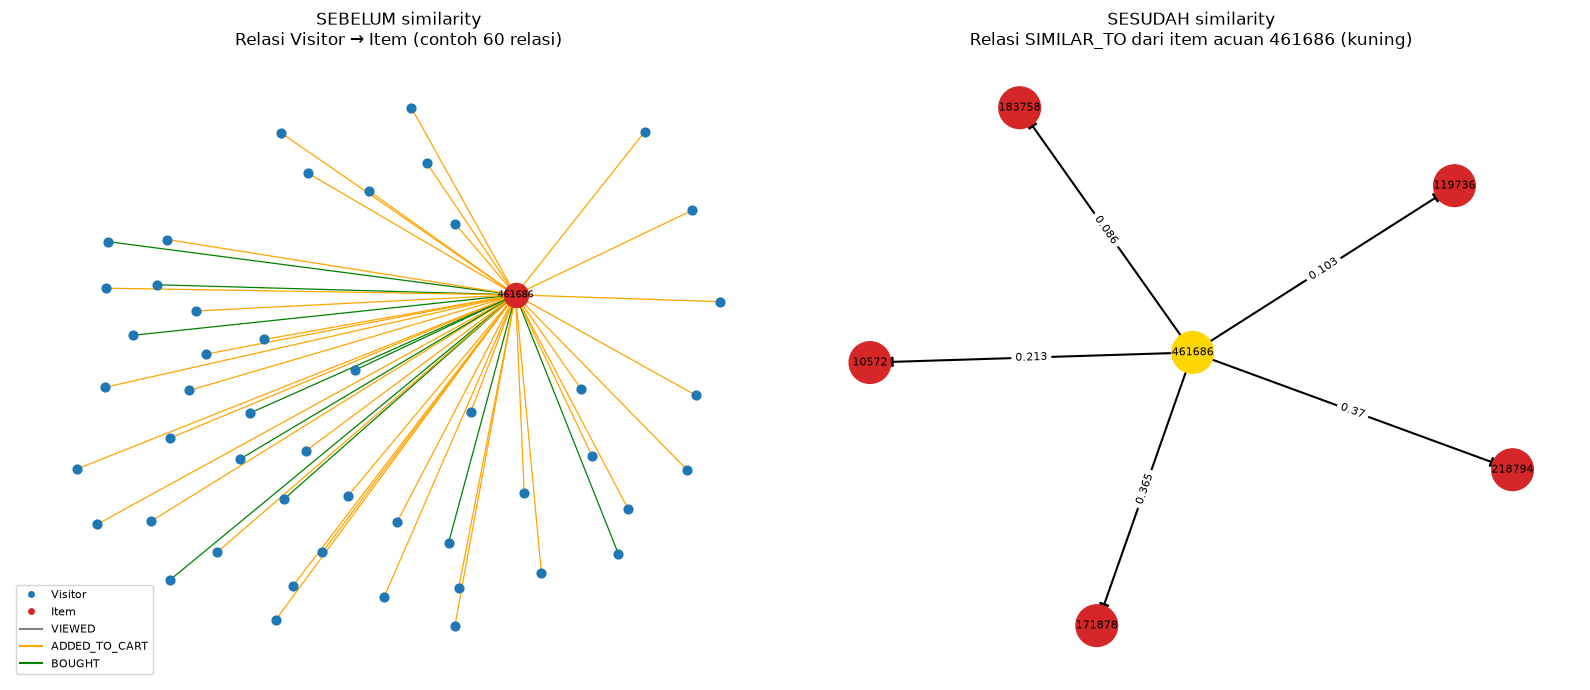

In [27]:
from matplotlib.lines import Line2D

# Fokus pada item acuan + 5 item paling mirip (hasil Soal 7)
focus_items = [int(anchor_item)] + [int(item_ids[i]) for i in similar_indices]

before_graph_query = """
MATCH (v:RR_RetailRocket:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:RR_RetailRocket:Item)
WHERE i.itemid IN $item_ids
RETURN v.visitorid AS visitorid, type(r) AS event, i.itemid AS itemid
LIMIT 60
"""
after_graph_query = """
MATCH (i1:RR_RetailRocket:Item {itemid: $anchor})-[r:SIMILAR_TO]->(i2:RR_RetailRocket:Item)
RETURN i1.itemid AS item1, r.score AS score, i2.itemid AS item2
ORDER BY score DESC
LIMIT 5
"""

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD)) as driver:
    with driver.session(database=NEO4J_DATABASE) as session:
        before_rows = [r.data() for r in session.run(before_graph_query, item_ids=focus_items)]
        after_rows = [r.data() for r in session.run(after_graph_query, anchor=int(anchor_item))]

# --- Graf SEBELUM: Visitor -> Item ---
G_before = nx.DiGraph()
for r in before_rows:
    v, i = f"V_{r['visitorid']}", f"I_{r['itemid']}"
    G_before.add_node(v, kind="Visitor")
    G_before.add_node(i, kind="Item")
    G_before.add_edge(v, i, event=r["event"])

# --- Graf SESUDAH: Item -[SIMILAR_TO]-> Item ---
G_after = nx.DiGraph()
for r in after_rows:
    G_after.add_edge(f"I_{r['item1']}", f"I_{r['item2']}", score=round(r["score"], 3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Panel kiri: sebelum similarity
ax = axes[0]
pos = nx.spring_layout(G_before, seed=42)
visitors = [n for n, d in G_before.nodes(data=True) if d["kind"] == "Visitor"]
items_b = [n for n, d in G_before.nodes(data=True) if d["kind"] == "Item"]
event_color = {"VIEWED": "gray", "ADDED_TO_CART": "orange", "BOUGHT": "green"}
nx.draw_networkx_nodes(G_before, pos, nodelist=visitors, node_size=40, node_color="tab:blue", ax=ax)
nx.draw_networkx_nodes(G_before, pos, nodelist=items_b, node_size=300, node_color="tab:red", ax=ax)
nx.draw_networkx_edges(
    G_before, pos, ax=ax, arrows=False, width=0.9,
    edge_color=[event_color[d["event"]] for _, _, d in G_before.edges(data=True)],
)
nx.draw_networkx_labels(G_before, pos, labels={n: n[2:] for n in items_b}, font_size=7, ax=ax)
ax.set_title("SEBELUM similarity\nRelasi Visitor → Item (contoh 60 relasi)")
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue", label="Visitor"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:red", label="Item"),
    Line2D([0], [0], color="gray", label="VIEWED"),
    Line2D([0], [0], color="orange", label="ADDED_TO_CART"),
    Line2D([0], [0], color="green", label="BOUGHT"),
], loc="lower left", fontsize=8)
ax.axis("off")

# Panel kanan: sesudah similarity
ax = axes[1]
pos2 = nx.spring_layout(G_after, seed=42)
node_colors = ["gold" if n == f"I_{int(anchor_item)}" else "tab:red" for n in G_after.nodes]
nx.draw_networkx_nodes(G_after, pos2, node_size=900, node_color=node_colors, ax=ax)
nx.draw_networkx_edges(G_after, pos2, ax=ax, arrows=True, arrowsize=15, width=1.5)
nx.draw_networkx_labels(G_after, pos2, labels={n: n[2:] for n in G_after.nodes}, font_size=8, ax=ax)
nx.draw_networkx_edge_labels(G_after, pos2, edge_labels=nx.get_edge_attributes(G_after, "score"), font_size=8, ax=ax)
ax.set_title(f"SESUDAH similarity\nRelasi SIMILAR_TO dari item acuan {int(anchor_item)} (kuning)")
ax.axis("off")

plt.tight_layout()
plt.show()

## 2.2 Analytics

### Soal 1

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

    (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

    (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [28]:
RANDOM_SEED = 42
K = 5        # k = 5 tetangga terdekat per item, sekaligus panjang daftar top-K untuk evaluasi
N_ADS = 3    # jumlah item yang diiklankan
rng = random.Random(RANDOM_SEED)

p1_user_items = p1_train.groupby("visitorid")["itemid"].apply(lambda s: set(map(int, s.unique())))
p2_user_items = p2_test.groupby("visitorid")["itemid"].apply(lambda s: set(map(int, s.unique())))
catalog_set = set(item_ids)

def reachable_relevant(user_id):
    """Item P2 yang ada di katalog dan belum dilihat user di P1."""
    return (p2_user_items.loc[user_id] & catalog_set) - p1_user_items.loc[user_id]

eligible_users = sorted(
    int(u) for u in (set(p1_user_items.index) & set(p2_user_items.index))
    if len(p1_user_items.loc[u] & catalog_set) > 0 and len(reachable_relevant(u)) > 0
)
if not eligible_users:
    raise ValueError("Tidak ada user yang memenuhi syarat untuk evaluasi P1/P2 dengan katalog terpilih.")

target_user = rng.choice(eligible_users)
seen_items = p1_user_items.loc[target_user]
actual_test_items = p2_user_items.loc[target_user]
relevant_items = reachable_relevant(target_user)
seen_catalog_items = seen_items & catalog_set

print(f"Jumlah user memenuhi syarat : {len(eligible_users):,}")
print(f"Seed pemilihan user         : {RANDOM_SEED}")
print(f"User terpilih               : {target_user}")
print(f"Item unik pada P1           : {len(seen_items):,}")
print(f"Item P2 (semua)             : {len(actual_test_items):,}")
print(f"Item P2 relevan (terjangkau): {len(relevant_items):,}")

# --- KNN item-based: ambil k tetangga terdekat dari tiap item yang pernah diakses user ---
def top_k_neighbors(item_id, k):
    idx = item_to_row[int(item_id)]
    scores = item_sim[idx].copy()
    scores[idx] = -1.0                              # item bukan tetangga dirinya sendiri
    order = np.argsort(-scores, kind="stable")      # urutan deterministik bila skor sama
    return [(item_ids[j], float(scores[j])) for j in order if scores[j] > 0][:k]

recommendation_scores = {}
neighbor_rows = []
for seen_item in sorted(seen_catalog_items):
    for rank, (cand, s) in enumerate(top_k_neighbors(seen_item, K), start=1):
        neighbor_rows.append({"item_dilihat": seen_item, "rank_tetangga": rank,
                              "item_tetangga": cand, "similarity": s})
        if cand in seen_items:                      # jangan rekomendasikan ulang item yang sudah dilihat
            continue
        recommendation_scores[cand] = recommendation_scores.get(cand, 0.0) + s

ranked_recommendations = sorted(recommendation_scores.items(), key=lambda x: (-x[1], x[0]))
recommendations = [int(item_id) for item_id, _ in ranked_recommendations[:K]]

print(f"\nTetangga terdekat (k = {K}) dari item yang pernah diakses:")
display(pd.DataFrame(neighbor_rows))

print("\nDaftar rekomendasi (skor = jumlah similarity dari tetangga):")
display(pd.DataFrame([
    {"rank": r, "itemid": item_id, "skor_agregat": score}
    for r, (item_id, score) in enumerate(ranked_recommendations[:K], start=1)
]))

print(f"\nItem yang diiklankan (top-{N_ADS}):")
for r, item_id in enumerate(recommendations[:N_ADS], start=1):
    print(f"Iklan {r}: Item {item_id}")

Jumlah user memenuhi syarat : 110
Seed pemilihan user         : 42
User terpilih               : 1073958
Item unik pada P1           : 50
Item P2 (semua)             : 8
Item P2 relevan (terjangkau): 1

Tetangga terdekat (k = 5) dari item yang pernah diakses:


,item_dilihat,rank_tetangga,item_tetangga,similarity
0,546,1,248455,0.311576
1,546,2,252344,0.243132
2,546,3,119736,0.126854
3,546,4,183758,0.101710
4,546,5,266512,0.098384
5,83366,1,295299,0.166759
6,83366,2,334401,0.035223
7,83366,3,272455,0.030802
8,83366,4,267051,0.030802
9,83366,5,546,0.019256



Daftar rekomendasi (skor = jumlah similarity dari tetangga):


,rank,itemid,skor_agregat
0,1,248455,0.311576
1,2,183758,0.287762
2,3,119736,0.259453
3,4,252344,0.243132
4,5,267236,0.179029



Item yang diiklankan (top-3):
Iklan 1: Item 248455
Iklan 2: Item 183758
Iklan 3: Item 119736


User dipilih secara acak dari daftar user yang memiliki interaksi pada P1 dan P2, menggunakan random.Random(42) pada daftar user yang sudah diurutkan, sehingga pemilihan dapat direproduksi. User juga harus memiliki minimal satu item P1 di dalam katalog similarity.

Rekomendasi dibuat dengan item-based KNN dengan k = 5. Untuk setiap item yang pernah diakses user pada P1, diambil 5 item tetangga terdekat berdasarkan cosine similarity (hanya yang bernilai positif, tanpa item itu sendiri). Tetangga yang sudah pernah diakses user dibuang agar tidak direkomendasikan ulang. Skor tiap kandidat adalah jumlah similarity dari tetangga yang menunjuk ke kandidat tersebut. Kandidat diurutkan menurut skor (ID item sebagai pemecah seri), lalu diambil top-5 sebagai daftar rekomendasi dan 3 teratas sebagai item yang diiklankan.

Data P2 tidak dipakai untuk membentuk rekomendasi. P2 hanya menjadi ground truth pada evaluasi Hit@5 dan NDCG@5.

### Soal 2

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

    (a) Hit@5

    (b) NDCG@5

In [29]:
relevant_items = set(map(int, relevant_items))   # ground truth yang terjangkau (sudah dihitung di sel Soal 1)
recommended_top_k = recommendations[:K]

# Hit@5: ada minimal satu item rekomendasi yang relevan pada testing.
hit_at_5 = int(any(item in relevant_items for item in recommended_top_k))

# DCG@5 untuk relevansi biner.
dcg_at_5 = sum(
    1.0 / math.log2(rank + 1)
    for rank, item in enumerate(recommended_top_k, start=1)
    if item in relevant_items
)

# IDCG berdasarkan jumlah item relevan yang dapat ditempatkan pada top-K.
ideal_relevant_count = min(len(relevant_items), K)
idcg_at_5 = sum(1.0 / math.log2(rank + 1) for rank in range(1, ideal_relevant_count + 1))
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

hits_list = [item for item in recommended_top_k if item in relevant_items]
print("User:", target_user)
print("Rekomendasi top-K:", recommended_top_k)
print("Item relevan pada testing:", sorted(relevant_items))
print("Item relevan yang ditemukan:", hits_list)
print(f"Hit@5  = {hit_at_5}")
print(f"DCG@5  = {dcg_at_5:.4f}")
print(f"IDCG@5 = {idcg_at_5:.4f}")
print(f"NDCG@5 = {ndcg_at_5:.4f}")

print("\nCatatan interpretasi:")
print("- Hit@5 = 1 berarti setidaknya satu item testing ditemukan di top-5; 0 berarti tidak ada.")
print("- NDCG@5 mendekati 1 bila item relevan berada di posisi atas.")
print("- Jika tidak ada item relevan di testing atau rekomendasi kosong, NDCG@5 dilaporkan 0.")

User: 1073958
Rekomendasi top-K: [248455, 183758, 119736, 252344, 267236]
Item relevan pada testing: [409804]
Item relevan yang ditemukan: []
Hit@5  = 0
DCG@5  = 0.0000
IDCG@5 = 1.0000
NDCG@5 = 0.0000

Catatan interpretasi:
- Hit@5 = 1 berarti setidaknya satu item testing ditemukan di top-5; 0 berarti tidak ada.
- NDCG@5 mendekati 1 bila item relevan berada di posisi atas.
- Jika tidak ada item relevan di testing atau rekomendasi kosong, NDCG@5 dilaporkan 0.


Evaluasi dilakukan pada user terpilih (1073958) dengan membandingkan 5 item rekomendasi dengan item ground truth. Ground truth adalah item yang diakses user pada P2, berada di katalog, dan belum pernah dilihat pada P1. User ini memiliki satu item relevan, yaitu 409804.

Hit@5 bernilai 1 jika setidaknya satu item relevan ada di top-5, dan 0 jika tidak ada. Daftar rekomendasi [248455, 183758, 119736, 252344, 267236] tidak memuat item 409804, sehingga Hit@5 = 0.

NDCG@5 menilai keberadaan sekaligus posisi item relevan: DCG@5 dibagi IDCG@5. Karena item relevan tidak muncul di top-5, DCG@5 = 0. Dengan satu item relevan, IDCG@5 = 1 (item relevan di peringkat 1), sehingga NDCG@5 = 0 / 1 = 0.

Hasil ini berarti sistem belum berhasil memprediksi item yang diakses user pada P2 untuk kasus ini. Hasil dari satu user tidak cukup untuk menilai kualitas sistem secara umum, karena dengan satu item relevan metrik hanya bisa bernilai 0 atau berada di nilai-nilai diskret tertentu, dan interaksi di data ini sangat jarang (sparse).